# Titanic Survival Prediction - Complete ML Pipeline

**Task 2 - End-to-end machine learning project**

**Note: keep `train.csv` and `test.csv` in the same folder as this notebook (they are included). Install libraries first with `pip install -r requirements.txt`. In Google Colab, upload both CSV files in the Files panel first.**

**Objective:** Predict which passengers survived the Titanic using passenger details, and compare different ML models.

**Pipeline**
1. Data Exploration
2. Feature Engineering
3. Model Training (Logistic Regression, Random Forest, XGBoost) with 5-fold cross-validation
4. Model Evaluation
5. Hyperparameter Tuning
6. Final Prediction (`submission.csv`)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, roc_curve, ConfusionMatrixDisplay

sns.set_style('whitegrid')
os.makedirs('images', exist_ok=True)
seed = 42

## 1. Data Exploration

### 1.1 Load train and test data

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print('Train shape:', train.shape)
print('Test shape:', test.shape)

Train shape: (891, 12)
Test shape: (418, 11)


In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


### 1.2 Feature types, missing values and unique values

In [5]:
info = pd.DataFrame({
    'dtype': train.dtypes.astype(str),
    'non_null': train.count(),
    'missing': train.isnull().sum(),
    'missing %': (train.isnull().sum() / len(train) * 100).round(2),
    'unique': train.nunique()
})
info

,dtype,non_null,missing,missing %,unique
PassengerId,int64,891,0,0.00,891
Survived,int64,891,0,0.00,2
Pclass,int64,891,0,0.00,3
Name,str,891,0,0.00,891
Sex,str,891,0,0.00,2
Age,float64,714,177,19.87,88
SibSp,int64,891,0,0.00,7
Parch,int64,891,0,0.00,7
Ticket,str,891,0,0.00,681
Fare,float64,891,0,0.00,248


In [6]:
print('Missing values in test data:')
print(test.isnull().sum()[test.isnull().sum() > 0])

Missing values in test data:
Age       86
Fare       1
Cabin    327
dtype: int64


**Feature types**
- **Target:** Survived (0 = died, 1 = survived)
- **Numerical:** Age, Fare, SibSp, Parch
- **Categorical:** Pclass, Sex, Embarked
- **Text / ID columns:** Name, Ticket, Cabin, PassengerId

Age has about 20% missing values, Cabin about 77% and Embarked only 2 rows. Test data also has 1 missing Fare.

### 1.3 Distribution of features

In [7]:
print(train[['Age', 'Fare', 'SibSp', 'Parch']].describe().round(2))
print()
print('Skewness:')
print(train[['Age', 'Fare', 'SibSp', 'Parch']].skew().round(2))

          Age    Fare   SibSp   Parch
count  714.00  891.00  891.00  891.00
mean    29.70   32.20    0.52    0.38
std     14.53   49.69    1.10    0.81
min      0.42    0.00    0.00    0.00
25%     20.12    7.91    0.00    0.00
50%     28.00   14.45    0.00    0.00
75%     38.00   31.00    1.00    0.00
max     80.00  512.33    8.00    6.00

Skewness:
Age      0.39
Fare     4.79
SibSp    3.70
Parch    2.75
dtype: float64


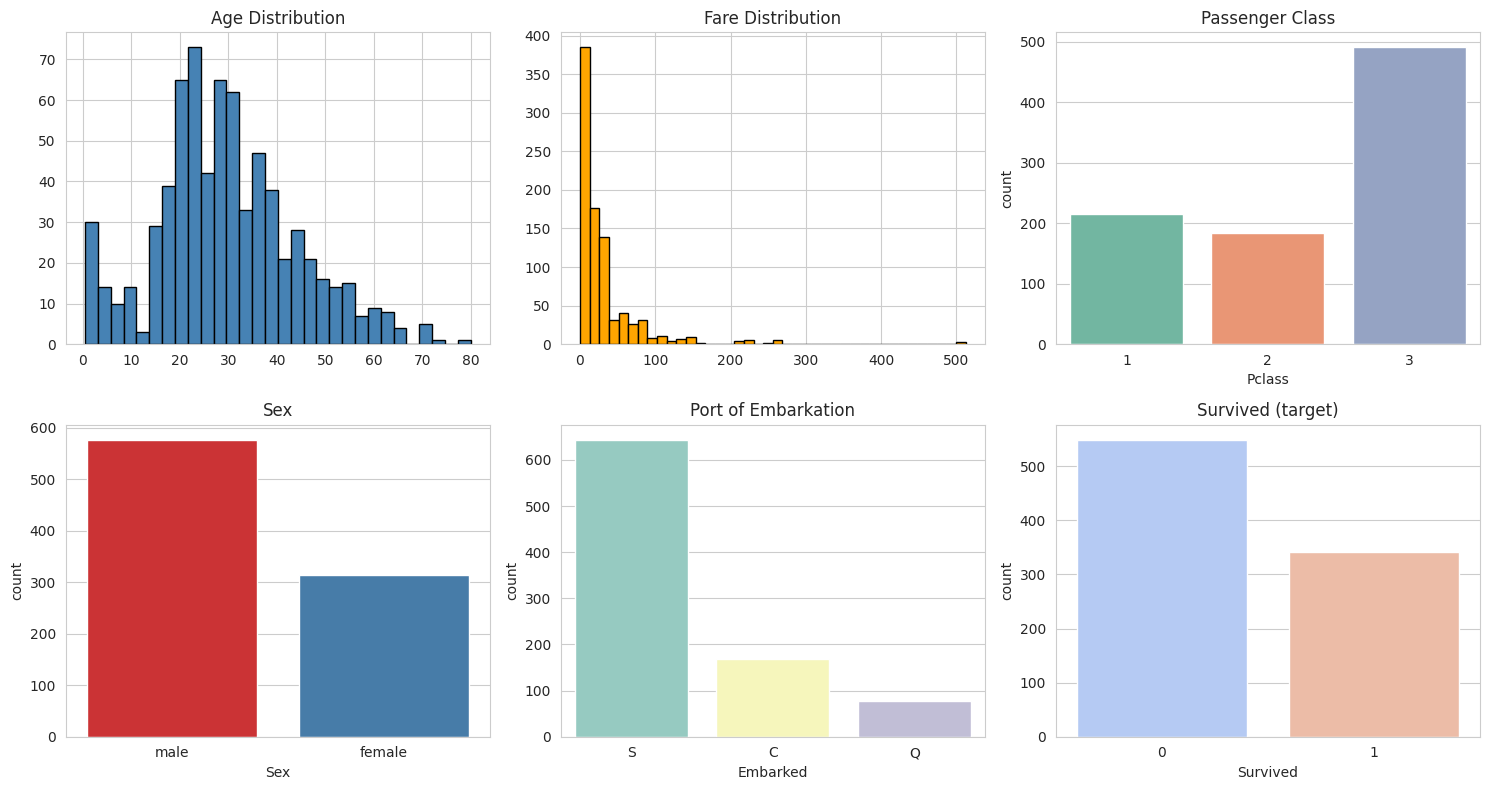

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))

ax[0, 0].hist(train['Age'].dropna(), bins=30, color='steelblue', edgecolor='black')
ax[0, 0].set_title('Age Distribution')

ax[0, 1].hist(train['Fare'], bins=40, color='orange', edgecolor='black')
ax[0, 1].set_title('Fare Distribution')

sns.countplot(x='Pclass', data=train, ax=ax[0, 2], palette='Set2')
ax[0, 2].set_title('Passenger Class')

sns.countplot(x='Sex', data=train, ax=ax[1, 0], palette='Set1')
ax[1, 0].set_title('Sex')

sns.countplot(x='Embarked', data=train, ax=ax[1, 1], palette='Set3')
ax[1, 1].set_title('Port of Embarkation')

sns.countplot(x='Survived', data=train, ax=ax[1, 2], palette='coolwarm')
ax[1, 2].set_title('Survived (target)')

plt.tight_layout()
plt.savefig('images/01_feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

Fare is strongly right skewed (a few very expensive tickets). Most passengers are in 3rd class, most are male, and most embarked at Southampton. The target is a bit imbalanced (about 38% survived).

### 1.4 Survival rate analysis

In [9]:
train['AgeGroup'] = pd.cut(train['Age'], bins=[0, 12, 18, 35, 60, 100], labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior'])

for col in ['Sex', 'Pclass', 'Embarked', 'AgeGroup']:
    print('Survival rate by', col)
    print((train.groupby(col)['Survived'].mean() * 100).round(1))
    print()

Survival rate by Sex
Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

Survival rate by Pclass
Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64

Survival rate by Embarked
Embarked
C    55.4
Q    39.0
S    33.7
Name: Survived, dtype: float64

Survival rate by AgeGroup
AgeGroup
Child          58.0
Teen           42.9
Young Adult    38.3
Adult          40.0
Senior         22.7
Name: Survived, dtype: float64



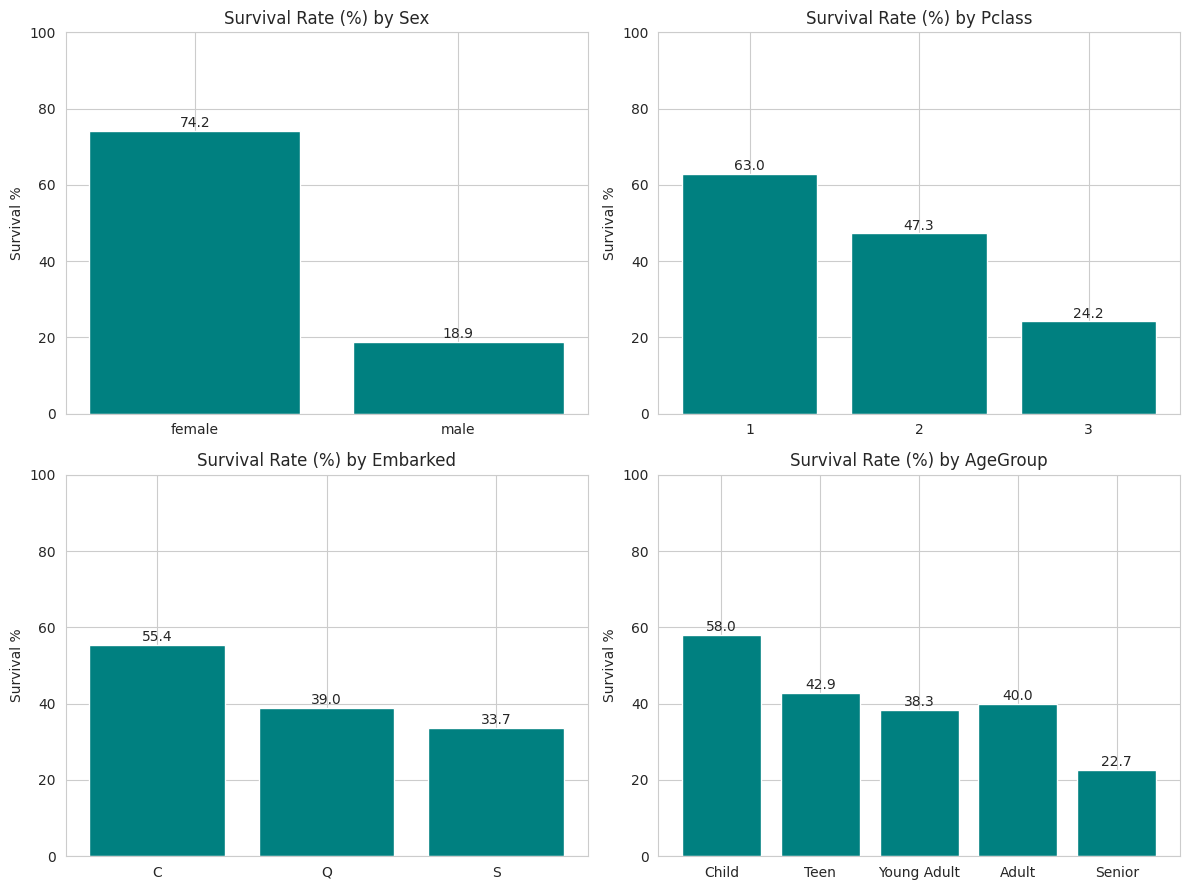

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

for i, col in enumerate(['Sex', 'Pclass', 'Embarked', 'AgeGroup']):
    rate = train.groupby(col)['Survived'].mean() * 100
    a = ax[i // 2, i % 2]
    a.bar(rate.index.astype(str), rate.values, color='teal')
    a.set_title('Survival Rate (%) by ' + col)
    a.set_ylabel('Survival %')
    a.set_ylim(0, 100)
    for j, v in enumerate(rate.values):
        a.text(j, v + 1, str(round(v, 1)), ha='center')

plt.tight_layout()
plt.savefig('images/02_survival_rates.png', dpi=150, bbox_inches='tight')
plt.show()

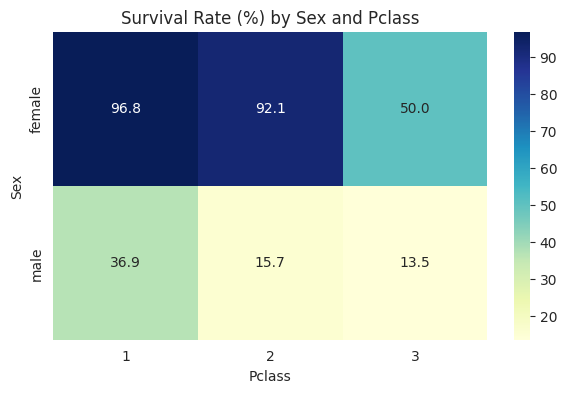

In [11]:
sex_class = train.pivot_table(values='Survived', index='Sex', columns='Pclass', aggfunc='mean') * 100

plt.figure(figsize=(7, 4))
sns.heatmap(sex_class, annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Survival Rate (%) by Sex and Pclass')
plt.savefig('images/03_sex_pclass_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

### 1.5 Correlation with survival

Survived    1.00
Sex         0.54
Fare        0.26
Parch       0.08
SibSp      -0.04
Age        -0.08
Pclass     -0.34
Name: Survived, dtype: float64


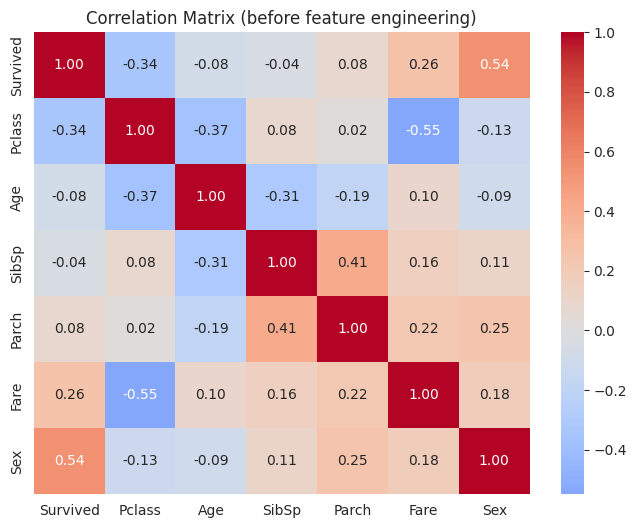

In [12]:
corr_data = train[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].copy()
corr_data['Sex'] = train['Sex'].map({'male': 0, 'female': 1})

corr = corr_data.corr().round(2)
print(corr['Survived'].sort_values(ascending=False))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Matrix (before feature engineering)')
plt.savefig('images/04_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

Sex has the strongest relation with survival (females survived much more), then Pclass (negative: higher class number means lower survival) and Fare (positive).

## 2. Feature Engineering

Steps:
- **Age:** fill with the median Age of each Pclass
- **Embarked:** fill with the mode
- **Fare:** (1 missing in test) fill with the median Fare of that Pclass
- **Cabin:** make a `Has_Cabin` column (1 if cabin is known)
- **New features:** `FamilySize = SibSp + Parch + 1`, `IsAlone`, `Title` (from Name), `AgeBin`
- **Encoding:** Sex as 0/1, one-hot encoding for Embarked, Title and AgeBin
- **Scaling:** StandardScaler on Age, Fare and FamilySize

The medians and mode are taken from the **train data only** and then used on test data.

In [13]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

age_medians = train.groupby('Pclass')['Age'].median()
fare_medians = train.groupby('Pclass')['Fare'].median()
embarked_mode = train['Embarked'].mode()[0]
print('Age medians per Pclass:')
print(age_medians)
print('Embarked mode:', embarked_mode)

Age medians per Pclass:
Pclass
1    37.0
2    29.0
3    24.0
Name: Age, dtype: float64
Embarked mode: S


In [14]:
def get_title(name):
    title = name.split(',')[1].split('.')[0].strip()
    return title

def make_features(data):
    df = data.copy()

    for p in [1, 2, 3]:
        df.loc[(df['Age'].isnull()) & (df['Pclass'] == p), 'Age'] = age_medians[p]
        df.loc[(df['Fare'].isnull()) & (df['Pclass'] == p), 'Fare'] = fare_medians[p]

    df['Embarked'] = df['Embarked'].fillna(embarked_mode)
    df['Has_Cabin'] = df['Cabin'].notnull().astype(int)

    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

    df['Title'] = df['Name'].apply(get_title)
    df['Title'] = df['Title'].replace(['Mlle', 'Ms'], 'Miss')
    df['Title'] = df['Title'].replace('Mme', 'Mrs')
    common = ['Mr', 'Mrs', 'Miss', 'Master']
    df['Title'] = df['Title'].apply(lambda t: t if t in common else 'Rare')

    df['AgeBin'] = pd.cut(df['Age'], bins=[0, 12, 18, 35, 60, 100], labels=['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior'])
    df['AgeBin'] = df['AgeBin'].astype(str)

    df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

    df = df.drop(columns=['Name', 'Ticket', 'Cabin'])
    return df

train_fe = make_features(train)
test_fe = make_features(test)

print(train_fe.isnull().sum().sum(), 'missing values left in train')
print(test_fe.isnull().sum().sum(), 'missing values left in test')
train_fe.head()

0 missing values left in train
0 missing values left in test


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Has_Cabin,FamilySize,IsAlone,Title,AgeBin
0,1,0,3,0,22.0,1,0,7.2500,S,0,2,0,Mr,YoungAdult
1,2,1,1,1,38.0,1,0,71.2833,C,1,2,0,Mrs,Adult
2,3,1,3,1,26.0,0,0,7.9250,S,0,1,1,Miss,YoungAdult
3,4,1,1,1,35.0,1,0,53.1000,S,1,2,0,Mrs,YoungAdult
4,5,0,3,0,35.0,0,0,8.0500,S,0,1,1,Mr,YoungAdult


### Survival rate by the new features

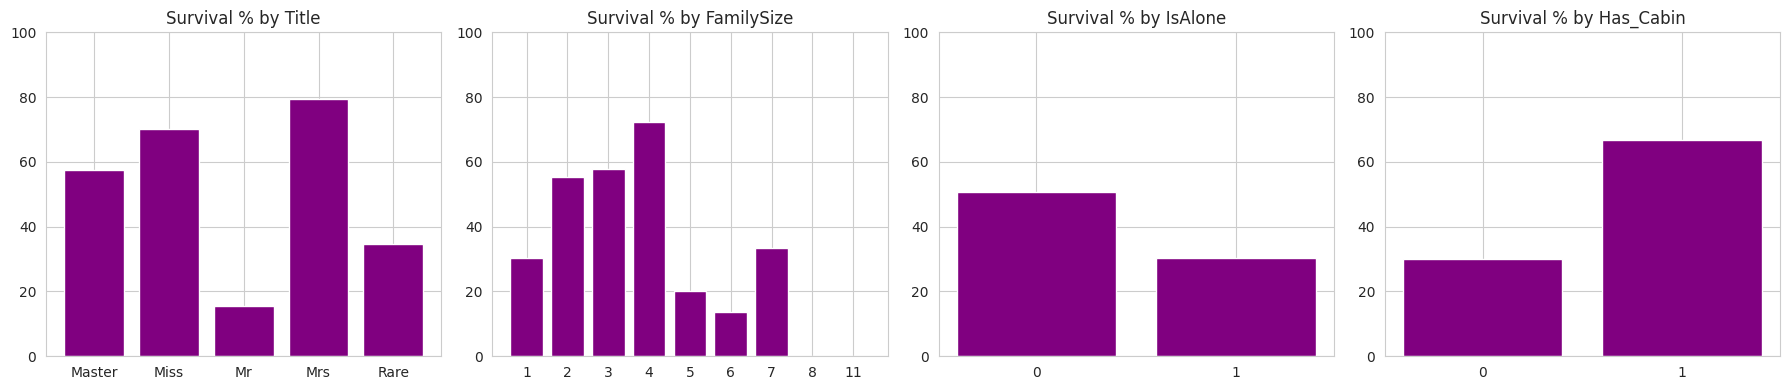

In [15]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))

for i, col in enumerate(['Title', 'FamilySize', 'IsAlone', 'Has_Cabin']):
    rate = train_fe.groupby(col)['Survived'].mean() * 100
    ax[i].bar(rate.index.astype(str), rate.values, color='purple')
    ax[i].set_title('Survival % by ' + col)
    ax[i].set_ylim(0, 100)

plt.tight_layout()
plt.savefig('images/05_new_features_survival.png', dpi=150, bbox_inches='tight')
plt.show()

Titles are very useful: Mrs, Miss and Master have high survival and Mr has very low. Has_Cabin passengers survived much more. Small families (2 to 4 people) survived more than people travelling alone or in very big families.

### Encoding

In [16]:
all_data = pd.concat([train_fe.drop(columns=['Survived']), test_fe], axis=0)
all_data = pd.get_dummies(all_data, columns=['Embarked', 'Title', 'AgeBin'], dtype=int)

X_all = all_data.iloc[:len(train_fe)].drop(columns=['PassengerId'])
X_test = all_data.iloc[len(train_fe):].drop(columns=['PassengerId'])
y_all = train_fe['Survived']

print('Train features:', X_all.shape)
print('Test features:', X_test.shape)
print(X_all.columns.tolist())

Train features: (891, 22)
Test features: (418, 22)
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Has_Cabin', 'FamilySize', 'IsAlone', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'AgeBin_Adult', 'AgeBin_Child', 'AgeBin_Senior', 'AgeBin_Teen', 'AgeBin_YoungAdult']


### Correlation with survival after feature engineering

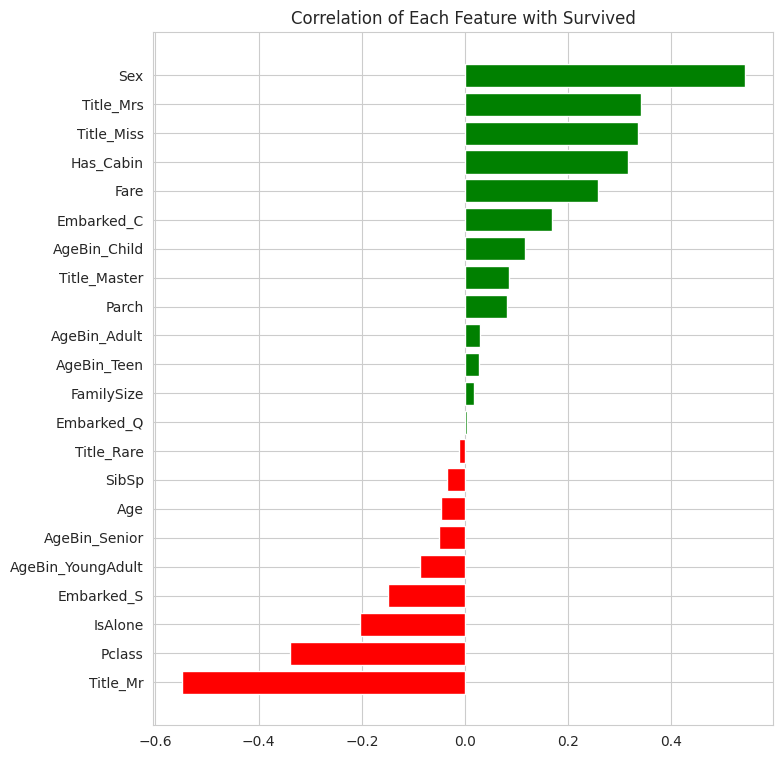

Title_Mr            -0.55
Pclass              -0.34
IsAlone             -0.20
Embarked_S          -0.15
AgeBin_YoungAdult   -0.09
AgeBin_Senior       -0.05
Age                 -0.05
SibSp               -0.04
Title_Rare          -0.01
Embarked_Q           0.00
FamilySize           0.02
AgeBin_Teen          0.03
AgeBin_Adult         0.03
Parch                0.08
Title_Master         0.09
AgeBin_Child         0.12
Embarked_C           0.17
Fare                 0.26
Has_Cabin            0.32
Title_Miss           0.34
Title_Mrs            0.34
Sex                  0.54
Name: Survived, dtype: float64


In [17]:
temp = X_all.copy()
temp['Survived'] = y_all.values
survival_corr = temp.corr()['Survived'].drop('Survived').sort_values()

plt.figure(figsize=(8, 9))
colors = ['red' if x < 0 else 'green' for x in survival_corr.values]
plt.barh(survival_corr.index, survival_corr.values, color=colors)
plt.title('Correlation of Each Feature with Survived')
plt.savefig('images/06_feature_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print(survival_corr.round(2))

## 3. Model Training

- **Split:** 80% train and 20% validation (stratified)
- **Scaling:** StandardScaler is fitted on the training part only, then used on validation and test
- **Models:** Logistic Regression, Random Forest, XGBoost
- **Cross-validation:** 5-fold (stratified) on the training part for every model

In [18]:
X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=seed)

print('Train:', X_train.shape, ' Validation:', X_val.shape)
print('Survival rate train:', round(y_train.mean(), 3), ' validation:', round(y_val.mean(), 3))

Train: (712, 22)  Validation: (179, 22)
Survival rate train: 0.383  validation: 0.385


In [19]:
scale_cols = ['Age', 'Fare', 'FamilySize']

scaler = StandardScaler()
X_train_s = X_train.copy()
X_val_s = X_val.copy()
X_train_s[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_val_s[scale_cols] = scaler.transform(X_val[scale_cols])

X_train_s.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Has_Cabin,FamilySize,IsAlone,Embarked_C,...,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare,AgeBin_Adult,AgeBin_Child,AgeBin_Senior,AgeBin_Teen,AgeBin_YoungAdult
692,3,0,-0.394592,0,0,0.513812,0,-0.556339,1,0,...,0,0,1,0,0,0,0,0,0,1
481,2,0,-0.017217,0,0,-0.662563,0,-0.556339,1,0,...,0,0,1,0,0,0,0,0,0,1
527,1,0,0.586583,0,0,3.955399,1,-0.556339,1,0,...,0,0,1,0,0,1,0,0,0,0
855,3,1,-0.847442,0,1,-0.467874,0,0.073412,0,0,...,0,0,0,1,0,0,0,0,1,0
801,2,1,0.133733,1,1,-0.115977,0,0.703162,0,0,...,0,0,0,1,0,0,0,0,0,1


In [20]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=seed),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=seed),
    'XGBoost': XGBClassifier(n_estimators=100, random_state=seed, eval_metric='logloss')
}

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

cv_results = {}
for name in models:
    acc = cross_val_score(models[name], X_train_s, y_train, cv=kfold, scoring='accuracy')
    f1 = cross_val_score(models[name], X_train_s, y_train, cv=kfold, scoring='f1')
    cv_results[name] = [acc.mean(), acc.std(), f1.mean(), f1.std()]

cv_table = pd.DataFrame(cv_results, index=['CV Accuracy', 'CV Acc Std', 'CV F1', 'CV F1 Std']).T.round(4)
cv_table

,CV Accuracy,CV Acc Std,CV F1,CV F1 Std
Logistic Regression,0.8315,0.0301,0.7779,0.0321
Random Forest,0.8146,0.0162,0.7527,0.0219
XGBoost,0.8146,0.0292,0.7543,0.0348


## 4. Model Evaluation

In [21]:
fitted = {}
preds = {}
probs = {}
rows = []

for name in models:
    model = models[name]
    model.fit(X_train_s, y_train)
    fitted[name] = model
    preds[name] = model.predict(X_val_s)
    probs[name] = model.predict_proba(X_val_s)[:, 1]

    rows.append([name,
                 accuracy_score(y_val, preds[name]),
                 precision_score(y_val, preds[name]),
                 recall_score(y_val, preds[name]),
                 f1_score(y_val, preds[name]),
                 roc_auc_score(y_val, probs[name])])

results = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']).set_index('Model').round(4)
results['CV F1 (5-fold)'] = cv_table['CV F1']
results

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,CV F1 (5-fold)
Model,,,,,,
Logistic Regression,0.8380,0.8030,0.7681,0.7852,0.8762,0.7779
Random Forest,0.8045,0.7429,0.7536,0.7482,0.8250,0.7527
XGBoost,0.8045,0.7429,0.7536,0.7482,0.8323,0.7543


### Confusion matrices

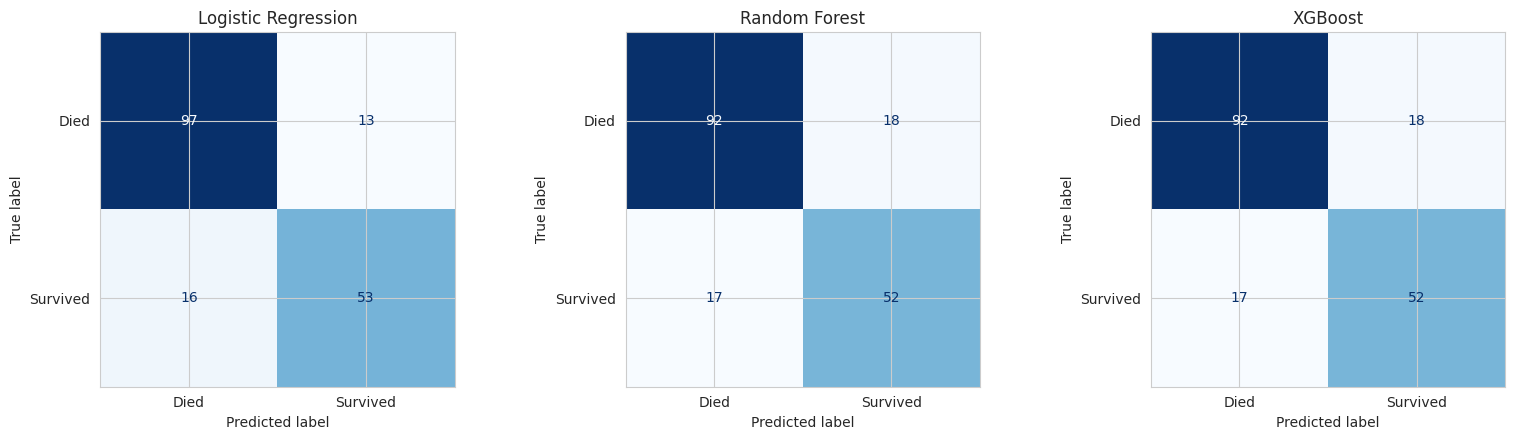

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

for i, name in enumerate(models):
    cm = confusion_matrix(y_val, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=['Died', 'Survived']).plot(ax=ax[i], cmap='Blues', colorbar=False)
    ax[i].set_title(name)

plt.tight_layout()
plt.savefig('images/07_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

### ROC curve comparison

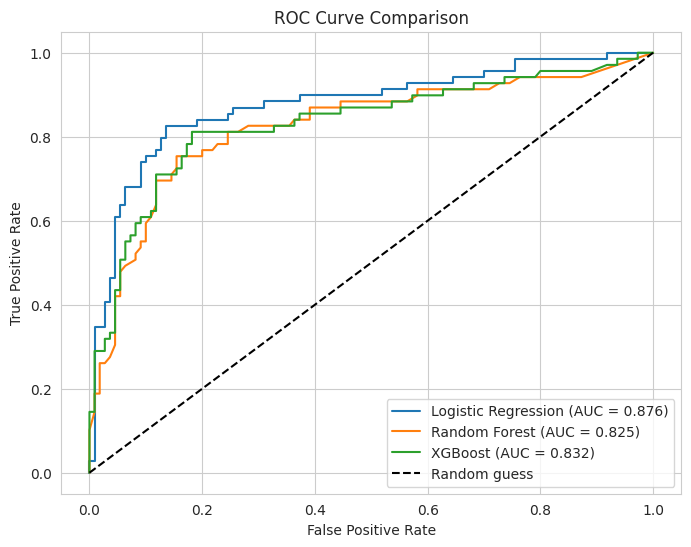

In [23]:
plt.figure(figsize=(8, 6))

for name in models:
    fpr, tpr, t = roc_curve(y_val, probs[name])
    plt.plot(fpr, tpr, label=name + ' (AUC = ' + str(round(roc_auc_score(y_val, probs[name]), 3)) + ')')

plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.savefig('images/08_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### Feature importance (tree based models)

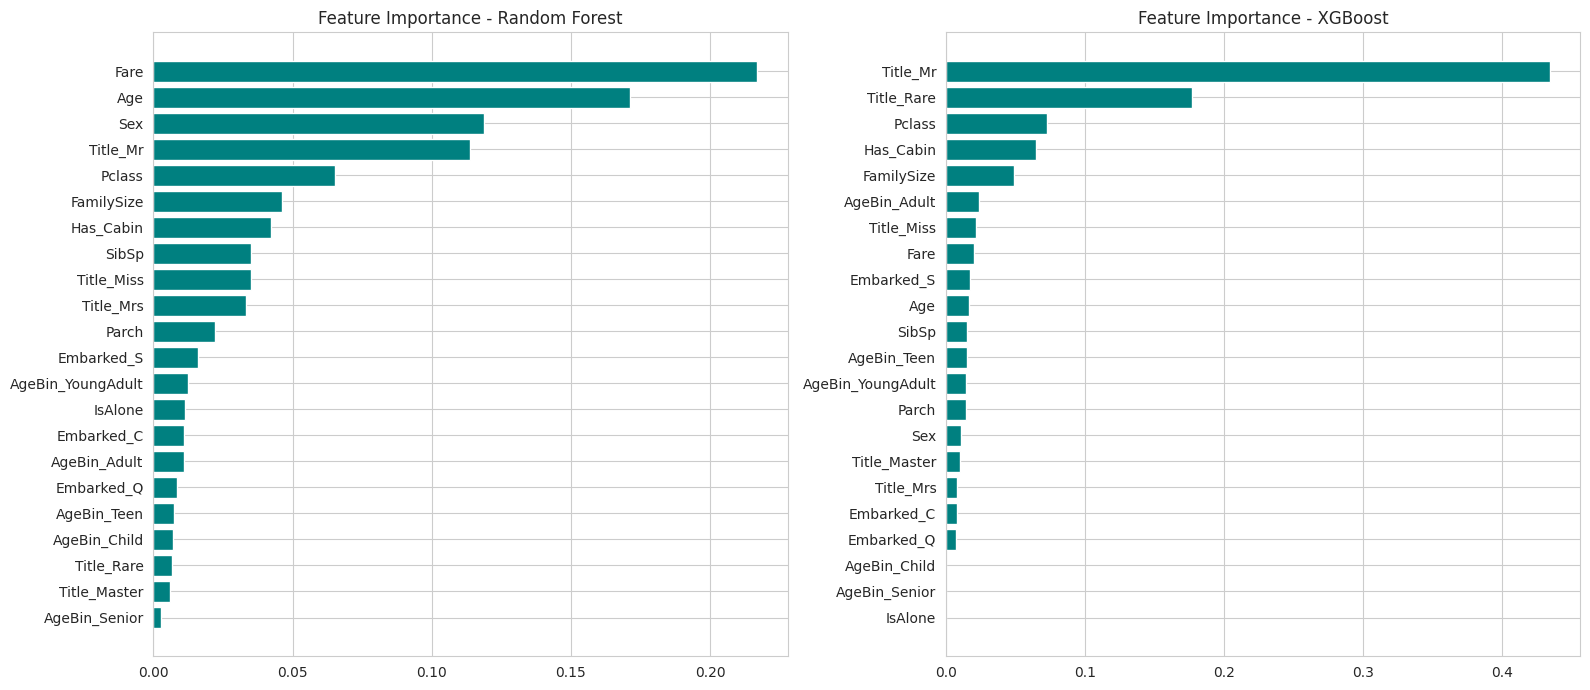

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))

for i, name in enumerate(['Random Forest', 'XGBoost']):
    imp = pd.Series(fitted[name].feature_importances_, index=X_train_s.columns).sort_values()
    ax[i].barh(imp.index, imp.values, color='teal')
    ax[i].set_title('Feature Importance - ' + name)

plt.tight_layout()
plt.savefig('images/09_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

### Select the best model based on F1-Score

In [25]:
best_name = results['F1-Score'].idxmax()
print('Best model by validation F1-Score:', best_name)
print('F1-Score:', results.loc[best_name, 'F1-Score'])
print()
print(results.sort_values('F1-Score', ascending=False))

Best model by validation F1-Score: Logistic Regression
F1-Score: 0.7852

                     Accuracy  Precision  Recall  F1-Score  AUC-ROC  \
Model                                                                 
Logistic Regression    0.8380     0.8030  0.7681    0.7852   0.8762   
Random Forest          0.8045     0.7429  0.7536    0.7482   0.8250   
XGBoost                0.8045     0.7429  0.7536    0.7482   0.8323   

                     CV F1 (5-fold)  
Model                                
Logistic Regression          0.7779  
Random Forest                0.7527  
XGBoost                      0.7543  


## 5. Hyperparameter Tuning

GridSearchCV is used on the best model with 5-fold cross-validation and F1-Score as the scoring metric. At least 4 hyperparameters are tuned. Performance is compared before and after tuning on the validation set.

In [26]:
if best_name == 'Random Forest':
    grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [4, 6, 8, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2']
    }
    base_model = RandomForestClassifier(random_state=seed)
elif best_name == 'XGBoost':
    grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [2, 3, 4, 6],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.7, 0.9, 1.0],
        'colsample_bytree': [0.7, 1.0]
    }
    base_model = XGBClassifier(random_state=seed, eval_metric='logloss')
else:
    grid = {
        'C': [0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear', 'saga'],
        'class_weight': [None, 'balanced']
    }
    base_model = LogisticRegression(max_iter=2000, random_state=seed)

print('Tuning:', best_name)
print('Hyperparameters:', list(grid.keys()))

Tuning: Logistic Regression
Hyperparameters: ['C', 'penalty', 'solver', 'class_weight']


In [27]:
grid_search = GridSearchCV(base_model, grid, cv=kfold, scoring='f1', n_jobs=-1)
grid_search.fit(X_train_s, y_train)

print('Best parameters:')
print(grid_search.best_params_)
print('Best CV F1-Score:', round(grid_search.best_score_, 4))

Best parameters:
{'C': 1, 'class_weight': None, 'penalty': 'l2', 'solver': 'saga'}
Best CV F1-Score: 0.7779


In [28]:
tuned_model = grid_search.best_estimator_
tuned_pred = tuned_model.predict(X_val_s)
tuned_prob = tuned_model.predict_proba(X_val_s)[:, 1]

before = results.loc[best_name, ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']].values.astype(float)
after = [accuracy_score(y_val, tuned_pred), precision_score(y_val, tuned_pred), recall_score(y_val, tuned_pred), f1_score(y_val, tuned_pred), roc_auc_score(y_val, tuned_prob)]

compare = pd.DataFrame({'Before Tuning': before, 'After Tuning': after}, index=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']).round(4)
compare['Change'] = (compare['After Tuning'] - compare['Before Tuning']).round(4)
compare

,Before Tuning,After Tuning,Change
Accuracy,0.8380,0.8380,0.0
Precision,0.8030,0.8030,0.0
Recall,0.7681,0.7681,0.0
F1-Score,0.7852,0.7852,0.0
AUC-ROC,0.8762,0.8762,0.0


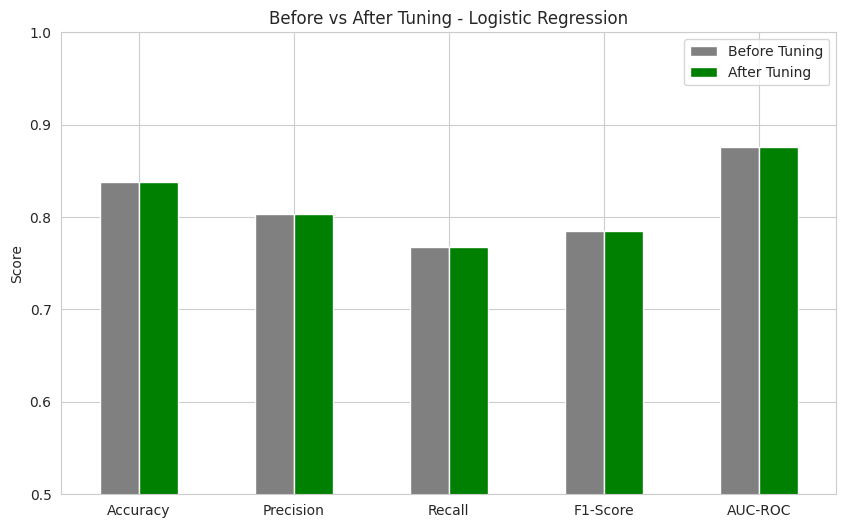

In [29]:
compare[['Before Tuning', 'After Tuning']].plot(kind='bar', figsize=(10, 6), color=['gray', 'green'])
plt.title('Before vs After Tuning - ' + best_name)
plt.ylabel('Score')
plt.ylim(0.5, 1)
plt.xticks(rotation=0)
plt.savefig('images/10_before_after_tuning.png', dpi=150, bbox_inches='tight')
plt.show()

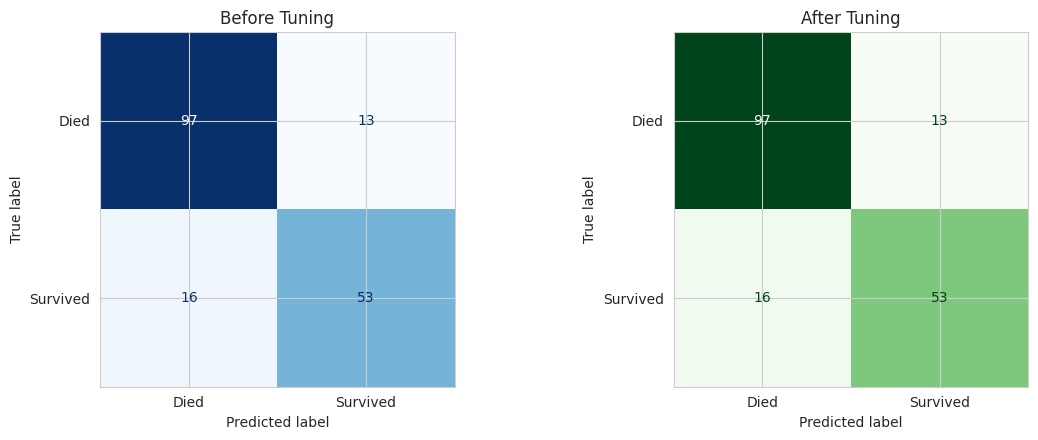

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_val, preds[best_name]), display_labels=['Died', 'Survived']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Before Tuning')
ConfusionMatrixDisplay(confusion_matrix(y_val, tuned_pred), display_labels=['Died', 'Survived']).plot(ax=ax[1], cmap='Greens', colorbar=False)
ax[1].set_title('After Tuning')

plt.tight_layout()
plt.savefig('images/11_confusion_before_after.png', dpi=150, bbox_inches='tight')
plt.show()

### Extra: tune the other two models as well

The tuning of the best model gave no change, so I also tune Random Forest and XGBoost with the same method to check if tuning lets them beat Logistic Regression.

In [31]:
extra_grids = {
    'Random Forest': (RandomForestClassifier(random_state=seed), {
        'n_estimators': [100, 200, 300],
        'max_depth': [4, 6, 8, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    }),
    'XGBoost': (XGBClassifier(random_state=seed, eval_metric='logloss'), {
        'n_estimators': [100, 200, 300],
        'max_depth': [2, 3, 4, 6],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.7, 0.9, 1.0]
    })
}

extra_rows = []
for name in extra_grids:
    gs = GridSearchCV(extra_grids[name][0], extra_grids[name][1], cv=kfold, scoring='f1', n_jobs=-1)
    gs.fit(X_train_s, y_train)
    p = gs.best_estimator_.predict(X_val_s)
    pr = gs.best_estimator_.predict_proba(X_val_s)[:, 1]
    extra_rows.append([name, 'Before', results.loc[name, 'F1-Score'], results.loc[name, 'AUC-ROC'], results.loc[name, 'Accuracy']])
    extra_rows.append([name, 'After', f1_score(y_val, p), roc_auc_score(y_val, pr), accuracy_score(y_val, p)])
    print(name, gs.best_params_)

extra_table = pd.DataFrame(extra_rows, columns=['Model', 'Tuning', 'F1-Score', 'AUC-ROC', 'Accuracy']).round(4)
extra_table

Random Forest {'max_depth': 4, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}


XGBoost {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.7}


,Model,Tuning,F1-Score,AUC-ROC,Accuracy
0,Random Forest,Before,0.7482,0.8250,0.8045
1,Random Forest,After,0.7328,0.8514,0.8045
2,XGBoost,Before,0.7482,0.8323,0.8045
3,XGBoost,After,0.7313,0.8370,0.7989


## 6. Final Prediction

The tuned model (with the best parameters) is trained again on the **full train data** (train + validation) and then used to predict `test.csv`. The scaler is also fitted again on the full train data.

In [32]:
final_scaler = StandardScaler()
X_full_s = X_all.copy()
X_test_s = X_test.copy()
X_full_s[scale_cols] = final_scaler.fit_transform(X_all[scale_cols])
X_test_s[scale_cols] = final_scaler.transform(X_test[scale_cols])

final_model = grid_search.best_estimator_.__class__(**grid_search.best_estimator_.get_params())
final_model.fit(X_full_s, y_all)

test_pred = final_model.predict(X_test_s)

submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': test_pred})
submission.to_csv('submission.csv', index=False)

print(submission.shape)
print(submission['Survived'].value_counts())
submission.head(10)

(418, 2)
Survived
0    247
1    171
Name: count, dtype: int64


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


In [33]:
check = pd.read_csv('submission.csv')
print(check.columns.tolist())
print('Rows:', len(check), ' (test rows:', len(test), ')')
print('Missing values:', check.isnull().sum().sum())
print('Same PassengerIds as test:', (check['PassengerId'] == test['PassengerId']).all())

['PassengerId', 'Survived']
Rows: 418  (test rows: 418 )
Missing values: 0
Same PassengerIds as test: True


## 7. Summary and Conclusions

**Model comparison (validation set, 20% stratified split)**

| Model | Accuracy | Precision | Recall | F1-Score | AUC-ROC | CV F1 (5-fold) |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.8380 | 0.8030 | 0.7681 | **0.7852** | 0.8762 | 0.7779 |
| Random Forest | 0.8045 | 0.7429 | 0.7536 | 0.7482 | 0.8250 | 0.7527 |
| XGBoost | 0.8045 | 0.7429 | 0.7536 | 0.7482 | 0.8323 | 0.7543 |

**What I found**
- **Best model: Logistic Regression** (highest F1-Score, AUC-ROC and cross-validation F1). Its confusion matrix has 97 correct deaths and 53 correct survivors out of 179 passengers.
- **Tuning:** GridSearchCV found `C=1, penalty=l2` as best, which is almost the same as the default model, so the score did not change (F1 0.7852 before and after). This means the default Logistic Regression was already a good setting.
- **Extra check:** After tuning, Random Forest (F1 0.7328, AUC 0.8514) and XGBoost (F1 0.7313, AUC 0.8370) still did not beat Logistic Regression. The Titanic data is small (891 rows) and the survival rules are fairly simple (sex, class, title), so a simple model works well and complex models over-fit more easily.
- **Important features:** Sex, Title (Mr, Mrs, Miss), Pclass, Has_Cabin and Fare. In XGBoost the top feature is `Title_Mr` and in Random Forest it is Fare, Age and Sex.
- **Feature engineering helped:** Title (correlation -0.55 for Mr), Has_Cabin (+0.32) and IsAlone (-0.20) all have a clear relation with survival.
- **Survival facts:** women 74.2% vs men 18.9%; 1st class 63.0% vs 3rd class 24.2%; children 58.0% vs seniors 22.7%.

**Limits:** the validation set has only 179 rows, so scores can change by a few percent with a different split. The difference between Random Forest and XGBoost is too small to be called real.

**Final output:** `submission.csv` with 418 rows (PassengerId, Survived), made with the tuned Logistic Regression trained on the full train data.